# Proyecto BERT: clasificación de sentimiento (IMDB)
**Autor:** Turpo Quispe Patty Milagros

Flujo del proyecto: (1) explorar datos → (2) tokenización WordPiece → (3) *fine-tuning* de `bert-base-uncased` → (4) evaluación → (5) demo de **embeddings contextuales** (polisemia) → (6) guardar modelo y figuras.



In [5]:
!pip -q install transformers datasets evaluate accelerate scikit-learn
import torch
print("GPU disponible:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (será lento)")

GPU disponible: True | Tesla T4


In [6]:
import os, random, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, pipeline)
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
MODEL_NAME = "bert-base-uncased"   # 12 capas, 768 hidden, 12 cabezas (110M parámetros)
MAX_LEN = 256
N_TRAIN, N_TEST = 8000, 2000       # sube N_TRAIN a 25000 si tienes tiempo
os.makedirs("figuras", exist_ok=True)

## 1. Datos y análisis exploratorio

In [7]:
ds = load_dataset("stanfordnlp/imdb")
print(ds)
train_raw = ds["train"].shuffle(seed=SEED).select(range(N_TRAIN))
test_raw  = ds["test"].shuffle(seed=SEED).select(range(N_TEST))
print("\nEjemplo:", train_raw[0]["text"][:300], "...", "| etiqueta:", train_raw[0]["label"])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Ejemplo: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot  ... | etiqueta: 1


/tmp/ipykernel_414/3979869176.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df.label.map({0:"NEGATIVE",1:"POSITIVE"}), ax=ax[0], palette=["#E06666","#6AA84F"])


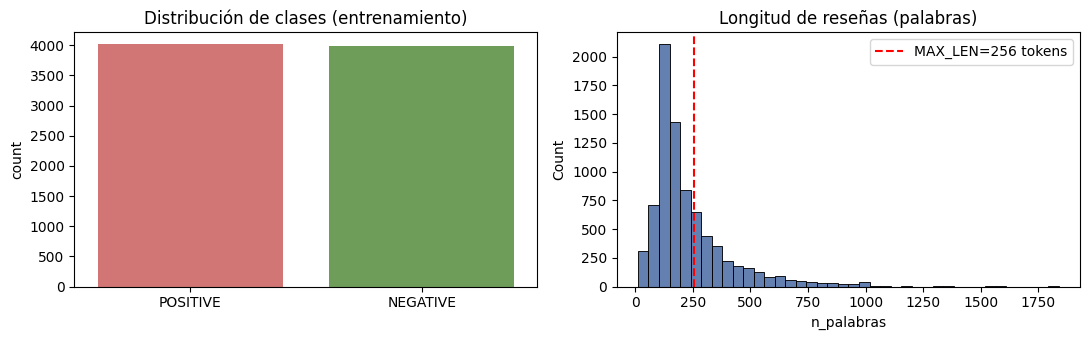

In [8]:
df = pd.DataFrame({"text": train_raw["text"], "label": train_raw["label"]})
df["n_palabras"] = df.text.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x=df.label.map({0:"NEGATIVE",1:"POSITIVE"}), ax=ax[0], palette=["#E06666","#6AA84F"])
ax[0].set_title("Distribución de clases (entrenamiento)"); ax[0].set_xlabel("")
sns.histplot(df.n_palabras, bins=40, ax=ax[1], color="#2F5597")
ax[1].axvline(MAX_LEN, color="red", ls="--", label=f"MAX_LEN={MAX_LEN} tokens"); ax[1].legend()
ax[1].set_title("Longitud de reseñas (palabras)")
plt.tight_layout(); plt.savefig("figuras/eda.png", dpi=200); plt.show()

## 2. Tokenización WordPiece
BERT añade `[CLS]` al inicio y `[SEP]` al final, y parte palabras raras en sub-palabras (`##`).

In [9]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
demo = "My dog is cute. He likes playing"
enc = tok(demo)
print(tok.convert_ids_to_tokens(enc["input_ids"]))
print("input_ids     :", enc["input_ids"])
print("token_type_ids:", enc["token_type_ids"], "  (segment embeddings)")
print("attention_mask:", enc["attention_mask"])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

['[CLS]', 'my', 'dog', 'is', 'cute', '.', 'he', 'likes', 'playing', '[SEP]']
input_ids     : [101, 2026, 3899, 2003, 10140, 1012, 2002, 7777, 2652, 102]
token_type_ids: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]   (segment embeddings)
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [10]:
def tokenize(batch):
    return tok(batch["text"], truncation=True, max_length=MAX_LEN)
train_ds = train_raw.map(tokenize, batched=True)
test_ds  = test_raw.map(tokenize, batched=True)
print(train_ds)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 8000
})


## 3. Modelo y *fine-tuning*
Se carga BERT pre-entrenado (MLM + NSP) y se añade una capa lineal de clasificación sobre la salida de `[CLS]`. Se ajustan **todos** los pesos con learning rate pequeño (2e-5).

In [12]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    id2label={0:"NEGATIVE",1:"POSITIVE"}, label2id={"NEGATIVE":0,"POSITIVE":1})
print(f"Parámetros totales: {sum(p.numel() for p in model.parameters())/1e6:.1f} M")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1}

args = TrainingArguments(
    output_dir="runs",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=150,  # Reemplaza a warmup_ratio=0.1
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    fp16=torch.cuda.is_available(),
    seed=SEED,
    report_to="none"
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=test_ds,
                  processing_class=tok, compute_metrics=compute_metrics)
trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parámetros totales: 109.5 M


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.247792,0.274810,0.890000,0.847594,0.951000,0.896324
2,0.251404,0.255861,0.911000,0.929019,0.890000,0.909091
3,0.079898,0.351557,0.908000,0.896887,0.922000,0.909270


TrainOutput(global_step=1500, training_loss=0.22426786883672079, metrics={'train_runtime': 332.4023, 'train_samples_per_second': 72.202, 'train_steps_per_second': 4.513, 'total_flos': 3157332664320000.0, 'train_loss': 0.22426786883672079, 'epoch': 3.0})

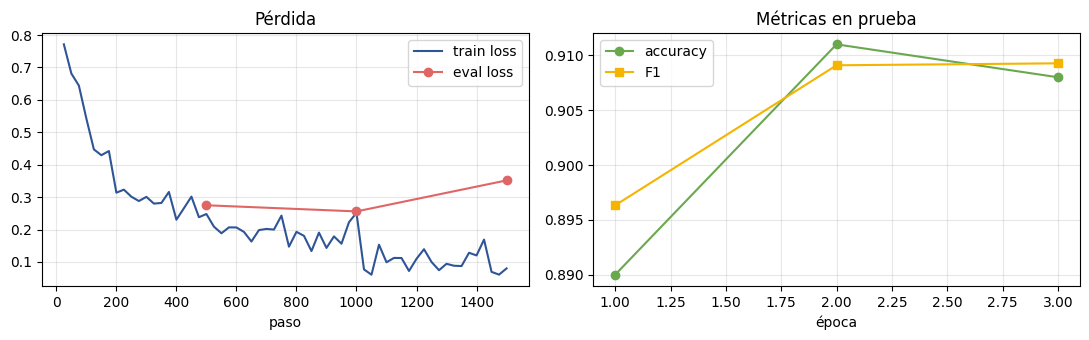

In [13]:
# Curvas de entrenamiento
log = pd.DataFrame(trainer.state.log_history)
tr = log.dropna(subset=["loss"]); ev = log.dropna(subset=["eval_loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(tr["step"], tr["loss"], label="train loss", color="#2F5597")
ax[0].plot(ev["step"], ev["eval_loss"], "o-", label="eval loss", color="#E06666")
ax[0].set_xlabel("paso"); ax[0].set_title("Pérdida"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ev["epoch"], ev["eval_accuracy"], "o-", label="accuracy", color="#6AA84F")
ax[1].plot(ev["epoch"], ev["eval_f1"], "s-", label="F1", color="#F4B400")
ax[1].set_xlabel("época"); ax[1].set_title("Métricas en prueba"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("figuras/curvas.png", dpi=200); plt.show()

## 4. Evaluación

              precision    recall  f1-score   support

    NEGATIVE     0.9198    0.8940    0.9067      1000
    POSITIVE     0.8969    0.9220    0.9093      1000

    accuracy                         0.9080      2000
   macro avg     0.9083    0.9080    0.9080      2000
weighted avg     0.9083    0.9080    0.9080      2000



Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.079898,0.351557,3,0.908000,0.896887,0.922000,0.909270


{'eval_loss': 0.35155707597732544, 'eval_accuracy': 0.908, 'eval_precision': 0.896887159533074, 'eval_recall': 0.922, 'eval_f1': 0.9092702169625246}


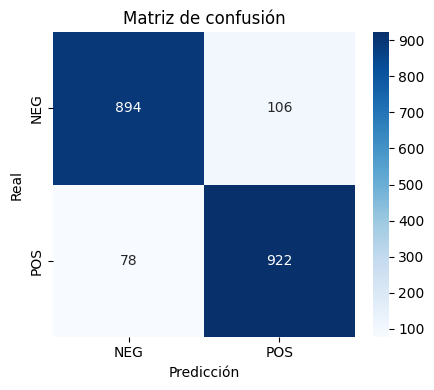

In [14]:
pred = trainer.predict(test_ds)
y_true, y_pred = pred.label_ids, np.argmax(pred.predictions, axis=-1)
print(classification_report(y_true, y_pred, target_names=["NEGATIVE","POSITIVE"], digits=4))
final = trainer.evaluate(); print(final)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["NEG","POS"], yticklabels=["NEG","POS"])
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión")
plt.tight_layout(); plt.savefig("figuras/confusion.png", dpi=200); plt.show()

In [15]:
# Errores del modelo (análisis cualitativo)
probs = torch.softmax(torch.tensor(pred.predictions), dim=-1).numpy()
err = np.where(y_true != y_pred)[0][:5]
for i in err:
    print(f"Real={'POS' if y_true[i] else 'NEG'} | Pred={'POS' if y_pred[i] else 'NEG'} "
          f"({probs[i].max():.2f}) | {test_raw[int(i)]['text'][:200]}...\n")

Real=NEG | Pred=POS (0.94) | Coming from Kiarostami, this art-house visual and sound exposition is a surprise. For a director known for his narratives and keen observation of humans, especially children, this excursion into minim...

Real=NEG | Pred=POS (0.79) | "An astronaut (Michael Emmet) dies while returning from a mission and his body is recovered by the military. The base where the dead astronaut is taken to becomes the scene of a bizarre invasion plan ...

Real=NEG | Pred=POS (0.98) | Film critics of the world, I apologize. It is your job to give advice to the moviegoing public so that they can wisely choose what to spend money on. But I ignored your advice and I have been deeply h...

Real=NEG | Pred=POS (1.00) | I used to always love the bill because of its great script and characters, but lately i feel as though it has turned into an emotional type of soap. If you look at promotional pictures/posters of the ...

Real=NEG | Pred=POS (1.00) | A truly masterful piece of filmmaki

In [16]:
clf = pipeline("text-classification", model=trainer.model, tokenizer=tok,
               device=0 if torch.cuda.is_available() else -1, truncation=True, max_length=MAX_LEN)
for t in ["This movie was absolutely fantastic, I loved every minute!",
          "A boring, predictable plot and terrible acting.",
          "Not bad at all, though I expected more from the director."]:
    print(clf(t)[0], "<-", t)

{'label': 'POSITIVE', 'score': 0.9979531764984131} <- This movie was absolutely fantastic, I loved every minute!
{'label': 'NEGATIVE', 'score': 0.9984114170074463} <- A boring, predictable plot and terrible acting.
{'label': 'POSITIVE', 'score': 0.8386136889457703} <- Not bad at all, though I expected more from the director.


## 5. Embeddings contextuales: el problema de la polisemia
Un embedding clásico da **un** vector a *apple*. BERT da un vector distinto según el contexto. Lo comprobamos con la similitud coseno de la palabra *apple* en tres frases (usando BERT pre-entrenado, sin fine-tuning).

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


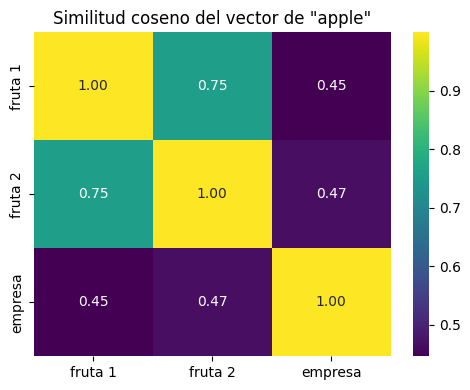

In [17]:
bert = AutoModel.from_pretrained(MODEL_NAME).to(trainer.model.device).eval()
def word_vec(sentence, word):
    inputs = tok(sentence, return_tensors="pt").to(bert.device)
    with torch.no_grad():
        h = bert(**inputs).last_hidden_state[0]
    toks = tok.convert_ids_to_tokens(inputs["input_ids"][0])
    return h[toks.index(word)].cpu()

sents = {"fruta 1": "An apple a day keeps the doctor away.",
         "fruta 2": "She ate a juicy red apple for lunch.",
         "empresa": "Smartphone companies including apple released a new phone."}
V = {k: word_vec(s, "apple") for k, s in sents.items()}
names = list(V); S = np.zeros((3, 3))
for i, a in enumerate(names):
    for j, b in enumerate(names):
        S[i, j] = torch.cosine_similarity(V[a], V[b], dim=0).item()
plt.figure(figsize=(5, 4))
sns.heatmap(S, annot=True, fmt=".2f", cmap="viridis", xticklabels=names, yticklabels=names)
plt.title('Similitud coseno del vector de "apple"'); plt.tight_layout()
plt.savefig("figuras/polisemia.png", dpi=200); plt.show()

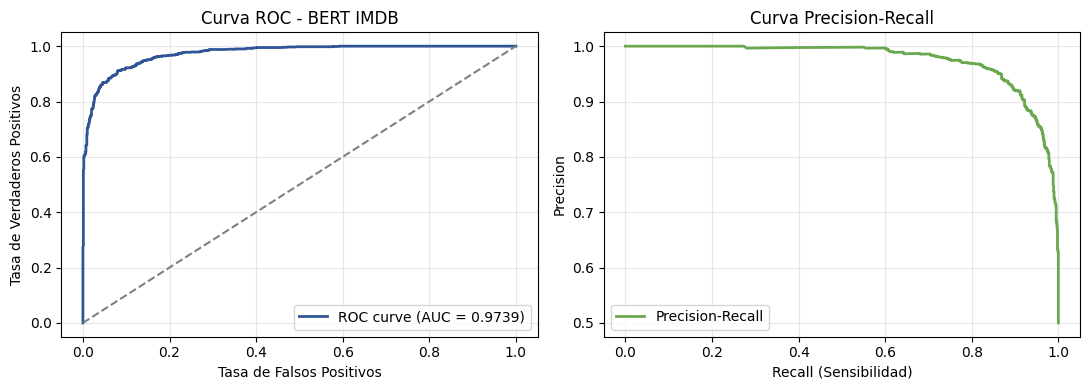

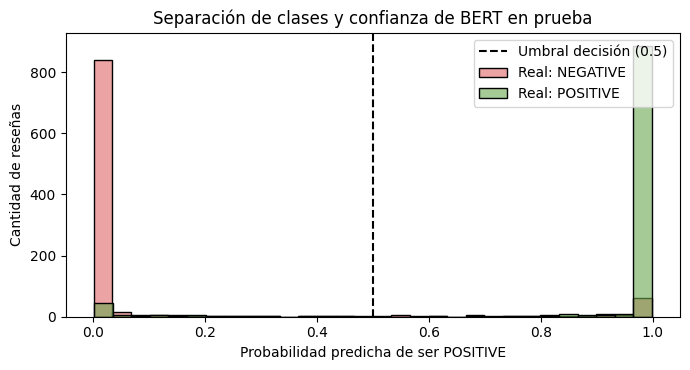

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


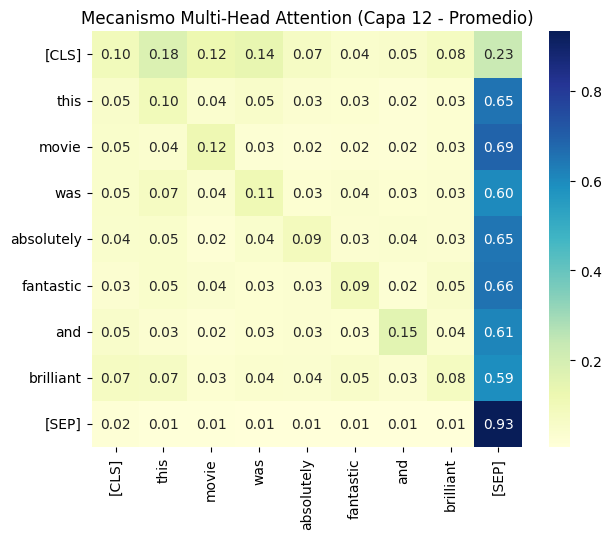

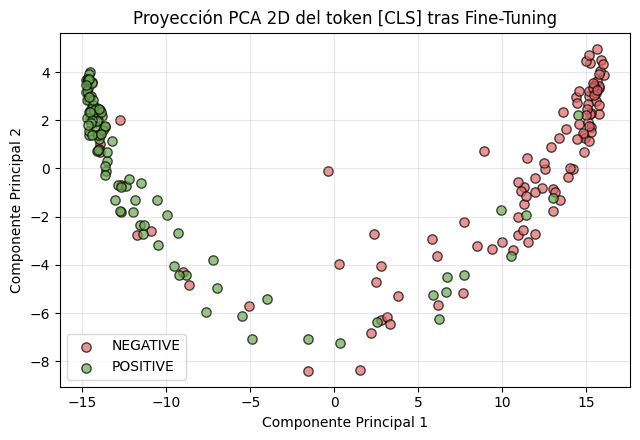

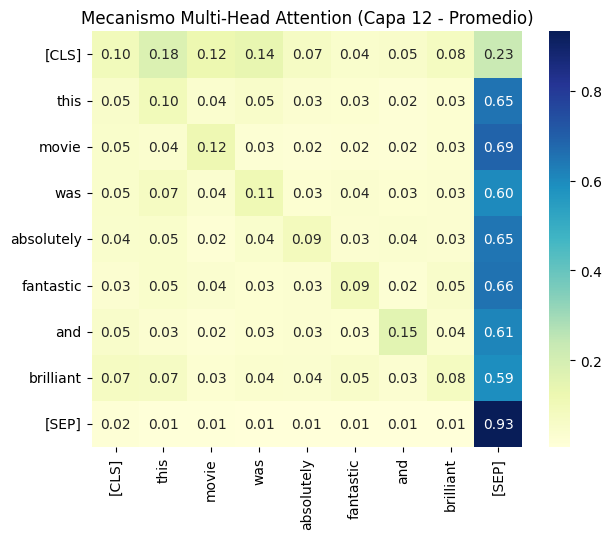

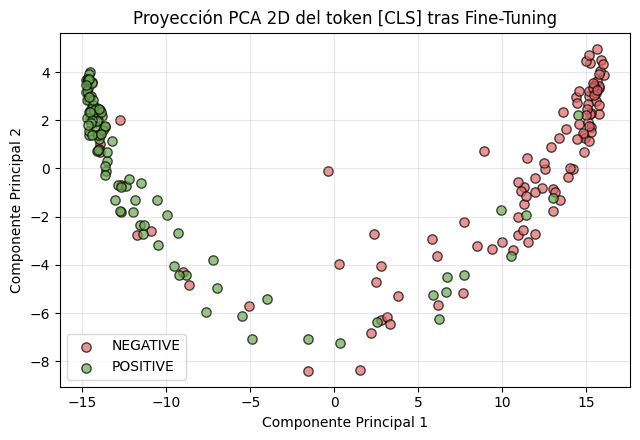

In [20]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.decomposition import PCA

# 1. Curva ROC y Curva Precision-Recall (Evaluación avanzada del clasificador)
fpr, tpr, _ = roc_curve(y_true, probs[:, 1])
roc_auc = auc(fpr, tpr)
prec, rec, _ = precision_recall_curve(y_true, probs[:, 1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr, color="#2F5597", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
ax[0].plot([0, 1], [0, 1], color="gray", ls="--")
ax[0].set_xlabel("Tasa de Falsos Positivos"); ax[0].set_ylabel("Tasa de Verdaderos Positivos")
ax[0].set_title("Curva ROC - BERT IMDB"); ax[0].legend(loc="lower right"); ax[0].grid(alpha=0.3)

ax[1].plot(rec, prec, color="#6AA84F", lw=2, label="Precision-Recall")
ax[1].set_xlabel("Recall (Sensibilidad)"); ax[1].set_ylabel("Precision")
ax[1].set_title("Curva Precision-Recall"); ax[1].legend(loc="lower left"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figuras/roc_pr.png", dpi=200); plt.show()

# 2. Distribución de confianza (probabilidades predichas)
plt.figure(figsize=(7, 3.8))
sns.histplot(probs[y_true == 0, 1], bins=30, color="#E06666", alpha=0.6, label="Real: NEGATIVE")
sns.histplot(probs[y_true == 1, 1], bins=30, color="#6AA84F", alpha=0.6, label="Real: POSITIVE")
plt.axvline(0.5, color="black", ls="--", label="Umbral decisión (0.5)")
plt.xlabel("Probabilidad predicha de ser POSITIVE"); plt.ylabel("Cantidad de reseñas")
plt.title("Separación de clases y confianza de BERT en prueba")
plt.legend(); plt.tight_layout(); plt.savefig("figuras/confianza.png", dpi=200); plt.show()

# 3. Mapa de Atención (Self-Attention de una cabeza del Transformer)
bert_att = AutoModel.from_pretrained(MODEL_NAME, attn_implementation="eager").to(bert.device).eval()
sample_text = "This movie was absolutely fantastic and brilliant"
inputs_att = tok(sample_text, return_tensors="pt").to(bert_att.device)
with torch.no_grad():
    out_att = bert_att(**inputs_att, output_attentions=True)

# Promedio de las 12 cabezas en la última capa (capa 12)
att_matrix = out_att.attentions[-1][0].mean(dim=0).cpu().numpy()
tokens_att = tok.convert_ids_to_tokens(inputs_att["input_ids"][0])

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(att_matrix, xticklabels=tokens_att, yticklabels=tokens_att, cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Mecanismo Multi-Head Attention (Capa 12 - Promedio)")
plt.tight_layout(); plt.savefig("figuras/atencion.png", dpi=200); plt.show()

# 4. Proyección PCA 2D de embeddings contextuales de [CLS] en reseñas de prueba
cls_vecs = []
subset_texts = test_raw["text"][:200]
subset_labels = test_raw["label"][:200]
for txt in subset_texts:
    inp = tok(txt, return_tensors="pt", truncation=True, max_length=128).to(trainer.model.device)
    with torch.no_grad():
        vec = trainer.model.bert(**inp).last_hidden_state[0, 0].cpu().numpy()
    cls_vecs.append(vec)

coords = PCA(n_components=2).fit_transform(cls_vecs)
plt.figure(figsize=(6.5, 4.5))
for lbl, name, col in [(0, "NEGATIVE", "#E06666"), (1, "POSITIVE", "#6AA84F")]:
    idx = np.array(subset_labels) == lbl
    plt.scatter(coords[idx, 0], coords[idx, 1], c=col, label=name, alpha=0.7, edgecolors="k", s=45)
plt.title("Proyección PCA 2D del token [CLS] tras Fine-Tuning")
plt.xlabel("Componente Principal 1"); plt.ylabel("Componente Principal 2")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig("figuras/pca_cls.png", dpi=200); plt.show()

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(att_matrix, xticklabels=tokens_att, yticklabels=tokens_att, cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Mecanismo Multi-Head Attention (Capa 12 - Promedio)")
plt.tight_layout(); plt.savefig("figuras/atencion.png", dpi=200); plt.show()

# 4. Proyección PCA 2D de embeddings contextuales de [CLS] en reseñas de prueba
cls_vecs = []
subset_texts = test_raw["text"][:200]
subset_labels = test_raw["label"][:200]
for txt in subset_texts:
    inp = tok(txt, return_tensors="pt", truncation=True, max_length=128).to(trainer.model.device)
    with torch.no_grad():
        vec = trainer.model.bert(**inp).last_hidden_state[0, 0].cpu().numpy()
    cls_vecs.append(vec)

coords = PCA(n_components=2).fit_transform(cls_vecs)
plt.figure(figsize=(6.5, 4.5))
for lbl, name, col in [(0, "NEGATIVE", "#E06666"), (1, "POSITIVE", "#6AA84F")]:
    idx = np.array(subset_labels) == lbl
    plt.scatter(coords[idx, 0], coords[idx, 1], c=col, label=name, alpha=0.7, edgecolors="k", s=45)
plt.title("Proyección PCA 2D del token [CLS] tras Fine-Tuning")
plt.xlabel("Componente Principal 1"); plt.ylabel("Componente Principal 2")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig("figuras/pca_cls.png", dpi=200); plt.show()